In [1]:
%reload_ext autoreload
%autoreload 2

## **Trabajo Práctico 2 - Reconstrucción 3D**

In [2]:
import os
import pickle
import cv2
import numpy as np
import utils

CARPETA_CALIB = "../data/calib"
CARPETA_CAPTURAS = "../data/captures"

### ***1. Calibración y rectificación estéreo***

#### Calibración de las cámaras

La calibración se realizó en clase con `calib-stereo`, la herramienta proporcionada por la cátedra. Los resultados se guardaron en archivos `.pkl`, que cargamos en este notebook para utilizarlos en la reconstrucción.

Para calibrar el sistema se utilizaron pares de imágenes de un tablero observado desde distintas posiciones y orientaciones. La geometría conocida del tablero permite establecer correspondencias entre las coordenadas 3D de sus esquinas y sus posiciones en las imágenes. A partir de estas correspondencias se estiman los parámetros de ambas cámaras y la relación espacial entre ellas.

Para cada cámara se obtiene una matriz intrínseca:

$$
K =
\begin{bmatrix}
f_x & 0 & p_x \\
0 & f_y & p_y \\
0 & 0 & 1
\end{bmatrix},
$$

donde $f_x$ y $f_y$ representan las distancias focales en píxeles, y $(p_x, p_y)$ indica la posición del punto principal. También se estiman los coeficientes de distorsión, que modelan las desviaciones introducidas por la lente respecto del modelo pinhole. En nuestra calibración se almacenan cinco coeficientes, en el orden $(k_1, k_2, p_1, p_2, k_3)$: tres corresponden a la distorsión radial y dos a la tangencial.

La calibración estéreo estima, además, la rotación $R$ y la traslación $T$ relativas entre las cámaras. Estos parámetros permiten transformar las coordenadas de un punto desde el sistema de la cámara izquierda al de la derecha:

$$
X_{\mathrm{der}} = R X_{\mathrm{izq}} + T.
$$

La distancia entre los centros de las cámaras, denominada *baseline*, se calcula como $B = \|T\|$. La escala métrica queda determinada por el tamaño físico del cuadrado ingresado durante la calibración: si este se expresa en milímetros, la traslación también queda expresada en esa unidad. Asimismo, se obtienen las matrices esencial $E$ y fundamental $F$, que describen la geometría epipolar del sistema.

A continuación, cargamos los parámetros desde `stereo_calibration.pkl` y los resultados de rectificación desde `stereo_maps.pkl`, y mostramos los valores obtenidos.

In [3]:
with open("../data/stereo_calibration.pkl", "rb") as f:
    calib_pkl = pickle.load(f)

with open("../data/stereo_maps.pkl", "rb") as f:
    mapas_pkl = pickle.load(f)

ancho, alto = calib_pkl["image_size"]
baseline_mm = np.linalg.norm(calib_pkl["T"])

print(f"Resolución de cada cámara: {ancho} × {alto} píxeles")
print(f"Baseline: {baseline_mm:.4f} mm")

parametros = [
    ("Matriz intrínseca izquierda K", "left_K"),
    ("Distorsión izquierda [k1, k2, p1, p2, k3]", "left_dist"),
    ("Matriz intrínseca derecha K", "right_K"),
    ("Distorsión derecha [k1, k2, p1, p2, k3]", "right_dist"),
    ("Rotación relativa R", "R"),
    ("Traslación relativa T (mm)", "T"),
    ("Matriz esencial E", "E"),
    ("Matriz fundamental F", "F"),
]

with np.printoptions(precision=5, suppress=False):
    for descripcion, clave in parametros:
        print(f"\n{descripcion}:")
        print(calib_pkl[clave])

Resolución de cada cámara: 1920 × 1080 píxeles
Baseline: 59.8382 mm

Matriz intrínseca izquierda K:
[[592.85926   0.      958.13416]
 [  0.      590.30506 558.32698]
 [  0.        0.        1.     ]]

Distorsión izquierda [k1, k2, p1, p2, k3]:
[[ 4.97460e-03 -2.41411e-02  2.04411e-05 -5.93168e-04  3.84636e-03]]

Matriz intrínseca derecha K:
[[592.85164   0.      950.28608]
 [  0.      590.4396  543.67339]
 [  0.        0.        1.     ]]

Distorsión derecha [k1, k2, p1, p2, k3]:
[[ 0.00232 -0.02265 -0.00031 -0.00114  0.00351]]

Rotación relativa R:
[[ 9.99974e-01 -3.94819e-04  7.20356e-03]
 [ 3.81765e-04  9.99998e-01  1.81341e-03]
 [-7.20427e-03 -1.81061e-03  9.99972e-01]]

Traslación relativa T (mm):
[[-5.98369e+01]
 [-1.09342e-02]
 [ 3.96611e-01]]

Matriz esencial E:
[[-7.26392e-05 -3.96591e-01 -1.16531e-02]
 [-3.44799e-02 -1.08498e-01  5.98381e+01]
 [-1.19097e-02 -5.98368e+01 -1.08430e-01]]

Matriz fundamental F:
[[-3.04383e-10 -1.66904e-06  9.03211e-04]
 [-1.45073e-07 -4.58475e-07

#### Error de reproyección
FIJARNOS ESTO
El error de reproyección permite evaluar qué tan bien se ajustan los parámetros estimados a las observaciones utilizadas para calibrar. Para calcularlo se proyectan los puntos conocidos del tablero sobre las imágenes y se comparan sus posiciones predichas con las esquinas detectadas. 

Los archivos `.pkl` disponibles contienen los parámetros de calibración y los mapas de rectificación, pero no incluyen el error RMS informado por la herramienta. Por lo tanto, queda pendiente recuperar este valor del registro de la calibración realizada en clase para incorporarlo al informe.

In [4]:
#COSASSS

#### Rectificación estéreo

Para calcular la profundidad de un punto observado en la imagen izquierda, necesitamos encontrar su correspondiente en la derecha. La geometría epipolar restringe esta búsqueda a una línea (linea epipolar), que puede estar inclinada y verse curvada por la distorsión de la lente.

La rectificación puede interpretarse como un “giro” de las cámaras. Junto con la corrección de distorsión, transforma las imágenes para que las líneas epipolares queden horizontales y los puntos correspondientes se encuentren sobre una misma fila. Así, la búsqueda se reduce a comparar posiciones horizontales. La diferencia entre las coordenadas horizontales de un mismo punto se denomina disparidad.

Durante la calibración en clase se calcularon y almacenaron:

- `R1` y `R2`: rotaciones de rectificación.
- `P1` y `P2`: matrices de proyección de las cámaras rectificadas.
- `Q`: matriz que permite convertir coordenadas de imagen y disparidad
  en coordenadas 3D del sistema de la cámara izquierda rectificada.
- Los mapas de rectificación de ambas imágenes.

Cargamos estos resultados desde `stereo_maps.pkl` y aplicamos los mapas mediante `cv2.remap`. Luego mostramos los pares originales y rectificados.

In [5]:
rect = {
    "R_izq": mapas_pkl["R1"],
    "R_der": mapas_pkl["R2"],
    "P_izq": mapas_pkl["P1"],
    "P_der": mapas_pkl["P2"],
    "Q": mapas_pkl["Q"],
    "mapa_izq": (
        mapas_pkl["left_map_x"],
        mapas_pkl["left_map_y"],
    ),
    "mapa_der": (
        mapas_pkl["right_map_x"],
        mapas_pkl["right_map_y"],
    ),
}

with np.printoptions(precision=8, suppress=False):
    for clave in ["R1", "R2", "P1", "P2", "Q"]:
        print(f"\n{clave}:")
        print(mapas_pkl[clave])


R1:
[[ 9.99999814e-01 -2.00079755e-04  5.75857423e-04]
 [ 1.99557762e-04  9.99999569e-01  9.06376416e-04]
 [-5.76038523e-04 -9.06261330e-04  9.99999423e-01]]

R2:
[[ 9.99978017e-01  1.82729861e-04 -6.62806297e-03]
 [-1.88736958e-04  9.99999572e-01 -9.05698409e-04]
 [ 6.62789463e-03  9.06929460e-04  9.99977624e-01]]

P1:
[[591.45692233   0.         956.1940918    0.        ]
 [  0.         591.45692233 551.47379303   0.        ]
 [  0.           0.           1.           0.        ]]

P2:
[[ 5.91456922e+02  0.00000000e+00  9.56194092e+02 -3.53917009e+04]
 [ 0.00000000e+00  5.91456922e+02  5.51473793e+02  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00  0.00000000e+00]]

Q:
[[ 1.00000000e+00  0.00000000e+00  0.00000000e+00 -9.56194092e+02]
 [ 0.00000000e+00  1.00000000e+00  0.00000000e+00 -5.51473793e+02]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  5.91456922e+02]
 [ 0.00000000e+00  0.00000000e+00  1.67117405e-02 -0.00000000e+00]]


Par estéreo 0


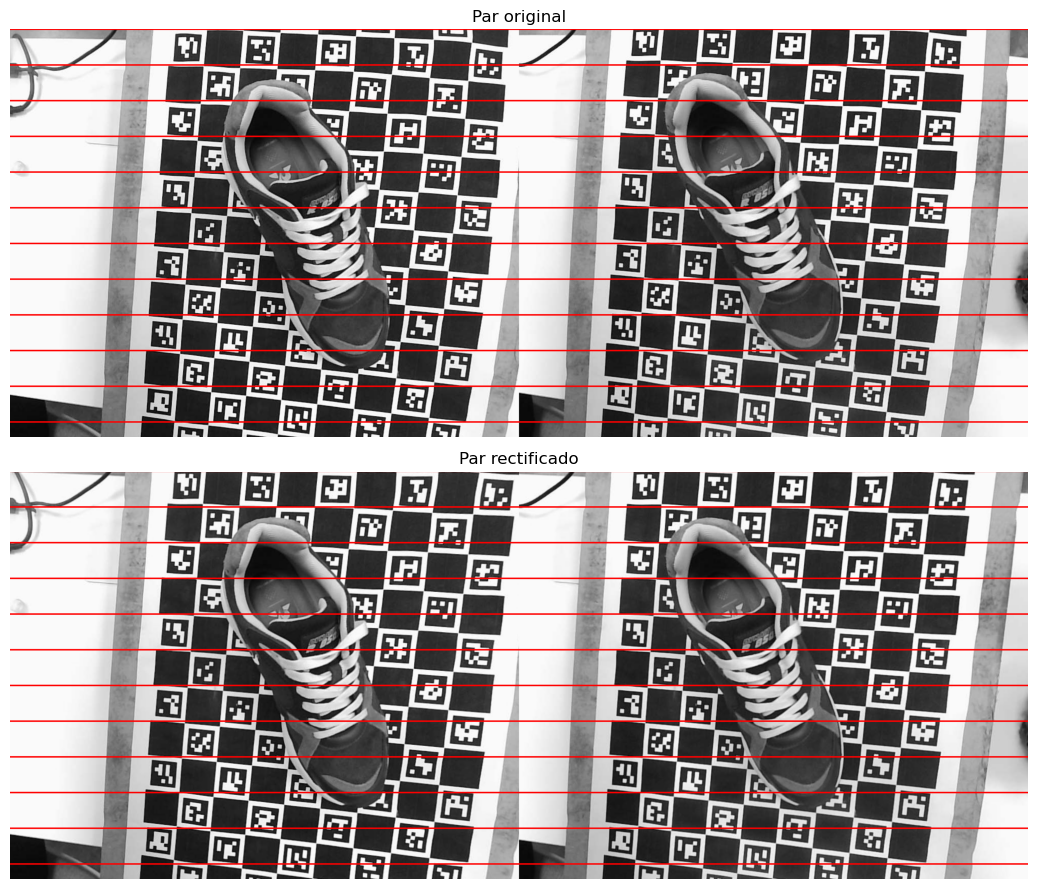

Par estéreo 10


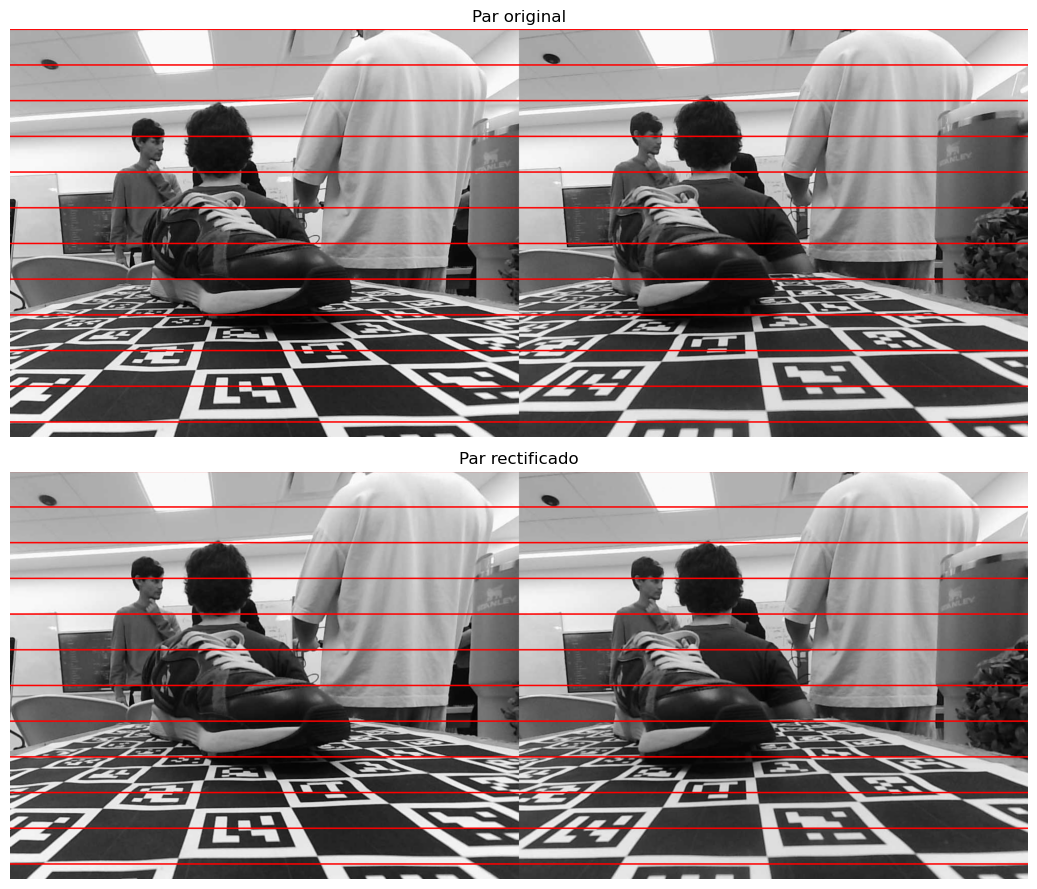

In [6]:
for indice in [0, 10]: # Mostramos dos pares estéreo de ejemplo
    img_izq = cv2.imread(os.path.join(CARPETA_CAPTURAS, f"left_{indice}.jpg"))
    img_der = cv2.imread(os.path.join(CARPETA_CAPTURAS, f"right_{indice}.jpg"))

    print(f"Par estéreo {indice}")
    utils.graficar_rectificacion(img_izq, img_der, rect, recorte = (50, 850, 550, 1550))

Las imágenes originales y rectificadas son similares, lo cual es consistente con la rotación relativa estimada entre las cámaras. Esta matriz es cercana a la identidad e indica que sus orientaciones ya eran muy parecidas antes de rectificar. Por este motivo, la transformación no produce un cambio marcado en la escena, aunque pueden observarse ajustes en los bordes y en el encuadre debidos a la corrección de distorsión y a la nueva proyección.

# ACA ESTA LO ANTERIRO ----------------------------------------------------------

### Estimación del tamaño del cuadrado
OpenCV necesita el tamaño real del cuadrado del tablero para que la calibración quede en milímetros. Como no lo conocíamos, calibramos primero con un cuadrado de **1** (sin unidades): así el baseline queda expresado en "cuadrados". Comparándolo con el baseline de la calibración de `calib-stereo` (59.838 mm), despejamos el lado del cuadrado en mm.


In [7]:
# # Calibramos con cuadrado = 1: el baseline queda medido en "cuadrados"
# obj_puntos_1, pts_izq_1, pts_der_1, img_size = utils.detectar_esquinas(CARPETA_CALIB, (9, 6), 1.0)
# calib_unitaria = utils.calibracion_estereo(obj_puntos_1, pts_izq_1, pts_der_1, img_size)

# baseline_cuadrados = np.linalg.norm(calib_unitaria["T"])   
# baseline_mm = np.linalg.norm(calib_pkl["T"])             

# print("Baseline en mm:", baseline_mm.round(4))

In [8]:
# # Si 2.137 cuadrados = 59.8382 mm, entonces 1 cuadrado = 59.8382 / 2.137 mm
# size_cuadrado_mm = baseline_mm / baseline_cuadrados
# print(f"Tamaño del cuadrado: {size_cuadrado_mm:.2f} mm")  

<p style="text-align: justify; text-justify: inter-word; font-size: 16px"> 
Como se busca calcular la profundidad de cada pixel de la imagen izquierda, necesitamos encontrar el mismo punto en la derecha. Sabemos que ese punto, siguiendo la geometria epipolar, cae sobre la linea epipolar que, originalmente se encuentra inclinada y por la distorsion, curva, por lo que la busqueda es costosa. 
</p>

<p style="text-align: justify; text-justify: inter-word; font-size: 16px"> 
Para ello, resulta util la rectificacion, con la cual se logra "girar" las camaras de forma que los planos imagen queden paralelos y las lineas epipolares horizontales y a la misma altura en ambas imagenes. Con esto, los puntos de la imagen izquierda se hallan a la misma altura en la derecha (en la misma fila), pero trasladados horizontalmente. Esto ultimo es la disparidad. 
</p>

In [9]:
# objetos_puntos, pts_izq, pts_der, img_size = utils.detectar_esquinas(CARPETA_CALIB, (9, 6), size_cuadrado_mm)
# calib = utils.calibracion_estereo(objetos_puntos, pts_izq, pts_der, img_size, True)
# rect = utils.rectificacion(calib_unitaria)

In [10]:
# # Verificamos la rectificacion
# img_izq = cv2.imread(os.path.join(CARPETA_CAPTURAS, "left_0.jpg"))
# img_der = cv2.imread(os.path.join(CARPETA_CAPTURAS, "right_0.jpg"))
# utils.graficar_rectificacion(img_izq, img_der, rect, recorte = (50, 850, 550, 1550), paso = 30, grosor = 2) 

### ***2. Disparidad, reconstrucción local y pose de las cámaras***

Una vez calibrado el sistema y rectificadas las imágenes, el siguiente paso consiste en recuperar la estructura 3D de la escena. Para cada par estéreo calcularemos un mapa de disparidad, a partir del cual obtendremos una nube de puntos local. Luego estimaremos la pose de la cámara respecto del tablero de referencia para expresar los puntos en un sistema de coordenadas común a todas las capturas.


#### *Stereo Matching*: Cálculo del mapa de disparidad

La rectificación permite buscar correspondencias sobre una misma fila de las imágenes izquierda y derecha. Para un punto visible en ambas, la disparidad se define como la diferencia entre sus coordenadas horizontales:

$$
d(u,v) = u_{\mathrm{izq}} - u_{\mathrm{der}}.
$$

Por otro lado, la profundidad se relaciona con la disparidad mediante:

$$
Z = \frac{fB}{d},
$$

donde $f$ es la distancia focal de la cámara rectificada en píxeles y $B$ es el baseline. Esta relación muestra que los puntos cercanos presentan mayor disparidad, mientras que los más lejanos presentan menor disparidad.

Como primera aproximación utilizaremos SGBM. Este método compara regiones de ambas imágenes y combina los costos de correspondencia en varias direcciones, favoreciendo una solución espacialmente coherente.

Comenzaremos con un par representativo para inspeccionar el mapa obtenido y ajustar los parámetros antes de extender el procedimiento al resto de las capturas. Tendremos en cuenta que las oclusiones, las regiones con poca textura y los patrones repetitivos pueden generar correspondencias incorrectas o disparidades inválidas.

In [11]:
# Cargamos un par de ejemplo y lo rectificamos
indice = 0

img_izq = cv2.imread(os.path.join(CARPETA_CAPTURAS, f"left_{indice}.jpg"))
img_der = cv2.imread(os.path.join(CARPETA_CAPTURAS, f"right_{indice}.jpg"))

img_izq_rect, img_der_rect = utils.rectificar(img_izq, img_der, rect) # Usamos imagenes completas

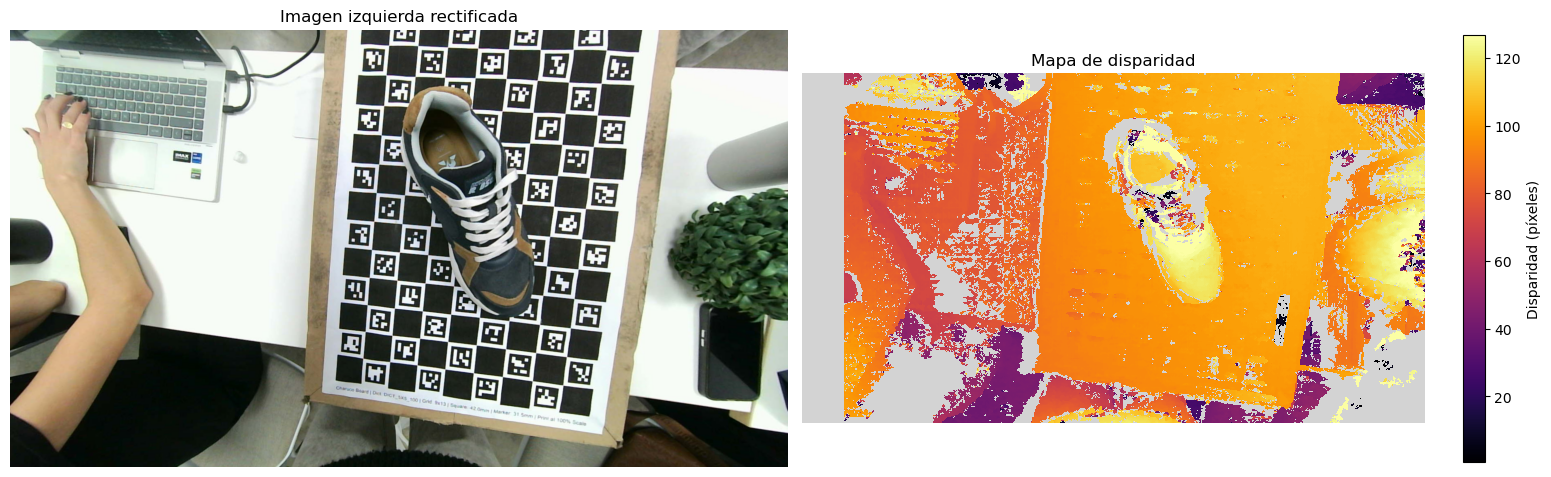

In [12]:
# Calculamos disparidad
disparidad = utils.calcular_disparidad(img_izq_rect, img_der_rect)

utils.graficar_disparidad(img_izq_rect, disparidad)

Con SGBM logramos distinguir la zapatilla del tablero, aunque todavía hay ruido y zonas sin disparidades válidas. Para evaluar otras opciones, usaremos `stereodemo`. Compararemos SGBM y CREStereo sobre los mismos pares rectificados y ajustaremos sus parámetros, observando los mapas de disparidad y las nubes de puntos para elegir cómo continuar la reconstrucción.

In [13]:
%pip install stereodemo

Note: you may need to restart the kernel to use updated packages.


In [14]:
import json
from pathlib import Path

carpeta_demo = Path("../data/prueba_stereodemo")
carpeta_demo.mkdir(parents=True, exist_ok=True)

for nombre, imagen in [
    ("left_0.png", img_izq_rect),
    ("right_0.png", img_der_rect),
]:
    if not cv2.imwrite(str(carpeta_demo / nombre), imagen):
        raise RuntimeError(f"No se pudo guardar {nombre}")

# Parámetros de las cámaras rectificadas
P1 = rect["P_izq"]
P2 = rect["P_der"]
alto, ancho = img_izq_rect.shape[:2]

# Separación horizontal del sistema rectificado, de mm a metros
baseline_rect_mm = abs(P2[0, 3] / P2[0, 0])

configuracion = {
    "width": ancho,
    "height": alto,
    "baseline_meters": float(baseline_rect_mm / 1000),
    "fx": float(P1[0, 0]),
    "fy": float(P1[1, 1]),
    "cx0": float(P1[0, 2]),
    "cx1": float(P2[0, 2]),
    "cy": float(P1[1, 2]),
    "depth_range": [0.05, 20.0],
    "left_image_rect_normalized": [0, 0, 1, 1],
}

with open(carpeta_demo / "stereodemo_calibration.json", "w", encoding="utf-8") as archivo:
    json.dump(configuracion, archivo, indent=4)